# 🛰️ Deep Learning Oil Spill Detection — Interactive Viva & Conceptual Masterclass
### *A Visual, First-Principles Guide to All "Why" and "What-If" Architectural Decisions*
**Course Module:** Deep Learning Mini-Project (AIML/DS)  
**Repository:** https://github.com/Shaunakrane914/DL_MiniProject

---
### 📌 What This Notebook Solves:
1. **Activation Functions:** Why **ReLU** in hidden layers? Why not Sigmoid, Tanh, or ELU? Why **Sigmoid** at the output?
2. **Loss Functions:** Why **BCE + Dice Loss**? Why does standard BCE alone fail on satellite images?
3. **Optimizers:** Why **Adam** instead of standard SGD? How does Momentum + RMSProp solve canyon oscillations?
4. **Data Normalization:** Why divide pixels by 255.0? (Spherical loss bowl vs. elongated canyon).
5. **Live Mini-Training & Segmentation:** A lightweight demonstration with interactive visual overlays.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import os
from PIL import Image

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
print("Libraries loaded successfully!")
print(f"TensorFlow Version: {tf.__version__}")


Libraries loaded successfully!
TensorFlow Version: 2.21.0


---
## 1. Activation Functions: Why ReLU? Why Sigmoid at Output?

### ❓ The Viva Questions:
* **Q1:** *Why didn't you use Sigmoid or Tanh in your hidden layers?*
* **Q2:** *What is the Vanishing Gradient problem and how does ReLU solve it?*
* **Q3:** *If ReLU is so great, why does the output layer use Sigmoid instead?*

Let's plot all activation functions and their **derivatives (gradients)** side-by-side to see the math in action!


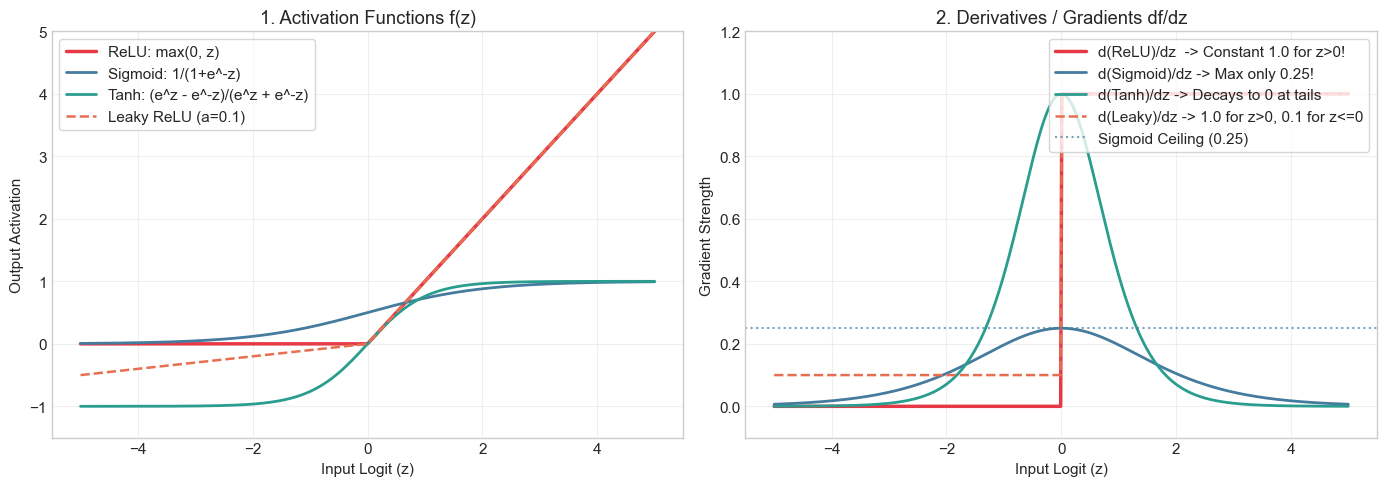

In [2]:
z = np.linspace(-5, 5, 500)

# 1. Activation Functions
relu = np.maximum(0, z)
sigmoid = 1 / (1 + np.exp(-z))
tanh = np.tanh(z)
leaky_relu = np.where(z > 0, z, 0.1 * z)
elu = np.where(z > 0, z, 1.0 * (np.exp(z) - 1))

# 2. Derivatives (Gradients)
grad_relu = np.where(z > 0, 1.0, 0.0)
grad_sigmoid = sigmoid * (1 - sigmoid)
grad_tanh = 1 - tanh**2
grad_leaky = np.where(z > 0, 1.0, 0.1)

# Plotting Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Activations
axes[0].plot(z, relu, label='ReLU: max(0, z)', linewidth=2.5, color='#e63946')
axes[0].plot(z, sigmoid, label='Sigmoid: 1/(1+e^-z)', linewidth=2, color='#457b9d')
axes[0].plot(z, tanh, label='Tanh: (e^z - e^-z)/(e^z + e^-z)', linewidth=2, color='#2a9d8f')
axes[0].plot(z, leaky_relu, label='Leaky ReLU (a=0.1)', linewidth=1.8, linestyle='--', color='#e76f51')
axes[0].set_title('1. Activation Functions f(z)')
axes[0].set_xlabel('Input Logit (z)')
axes[0].set_ylabel('Output Activation')
axes[0].set_ylim(-1.5, 5)
axes[0].legend(loc='upper left', frameon=True)
axes[0].grid(True, alpha=0.3)

# Plot Derivatives
axes[1].plot(z, grad_relu, label='d(ReLU)/dz  -> Constant 1.0 for z>0!', linewidth=2.5, color='#e63946')
axes[1].plot(z, grad_sigmoid, label='d(Sigmoid)/dz -> Max only 0.25!', linewidth=2, color='#457b9d')
axes[1].plot(z, grad_tanh, label='d(Tanh)/dz -> Decays to 0 at tails', linewidth=2, color='#2a9d8f')
axes[1].plot(z, grad_leaky, label='d(Leaky)/dz -> 1.0 for z>0, 0.1 for z<=0', linewidth=1.8, linestyle='--', color='#e76f51')
axes[1].set_title('2. Derivatives / Gradients df/dz')
axes[1].set_xlabel('Input Logit (z)')
axes[1].set_ylabel('Gradient Strength')
axes[1].axhline(0.25, color='#457b9d', linestyle=':', alpha=0.7, label='Sigmoid Ceiling (0.25)')
axes[1].set_ylim(-0.1, 1.2)
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 🔬 Visualizing the 16-Layer Vanishing Gradient Problem
When an error flows backward through our **16-layer deep U-Net**, the gradients multiply at each layer by the chain rule:
$$\text{Gradient at Layer } L = \prod_{l=1}^{L} \frac{df_l}{dz_l}$$
Let us watch what happens to the gradient signal as it travels back across 16 layers using **Sigmoid vs ReLU**:


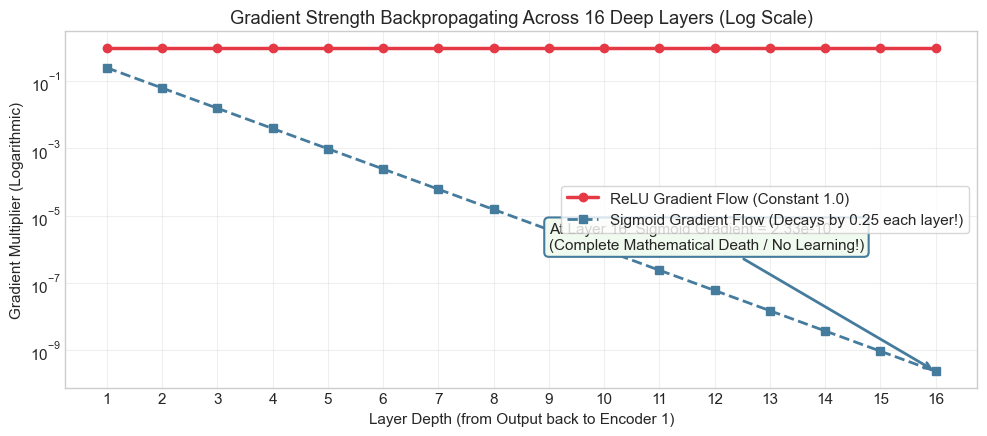

In [3]:
layers_idx = np.arange(1, 17)

# Best-case scenario for Sigmoid: gradient is at its absolute maximum (0.25) at every layer
sigmoid_grad_flow = (0.25) ** layers_idx

# ReLU: gradient is 1.0 for all active neurons
relu_grad_flow = (1.0) ** layers_idx

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.semilogy(layers_idx, relu_grad_flow, 'o-', color='#e63946', linewidth=2.5, label='ReLU Gradient Flow (Constant 1.0)')
ax.semilogy(layers_idx, sigmoid_grad_flow, 's--', color='#457b9d', linewidth=2, label='Sigmoid Gradient Flow (Decays by 0.25 each layer!)')

ax.set_title('Gradient Strength Backpropagating Across 16 Deep Layers (Log Scale)')
ax.set_xlabel('Layer Depth (from Output back to Encoder 1)')
ax.set_ylabel('Gradient Multiplier (Logarithmic)')
ax.set_xticks(layers_idx)
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc='center right', frameon=True)

# Annotate the dramatic vanishing
ax.annotate(f'At Layer 16: Sigmoid Gradient = {sigmoid_grad_flow[-1]:.2e}\n(Complete Mathematical Death / No Learning!)',
            xy=(16, sigmoid_grad_flow[-1]), xytext=(9, 1e-6),
            arrowprops=dict(arrowstyle="->", color='#457b9d', lw=2),
            bbox=dict(boxstyle="round,pad=0.3", fc="#f1faee", ec="#457b9d", lw=1.5))

plt.tight_layout()
plt.show()


---
## 2. Loss Functions: Why BCE + Dice Loss?

### ❓ The Viva Questions:
* **Q1:** *Why did you use a compound loss instead of standard Binary Cross-Entropy (BCE)?*
* **Q2:** *What is the 'Accuracy Paradox' in oil spill segmentation?*
* **Q3:** *Why does Dice Loss prevent the model from predicting 100% clean water?*

In marine satellite imagery, **over 98% of pixels are clean water** and **less than 2% are oil spills**.  
Let us simulate a lazy model that predicts all zeros (water everywhere) to see how BCE and Dice react!


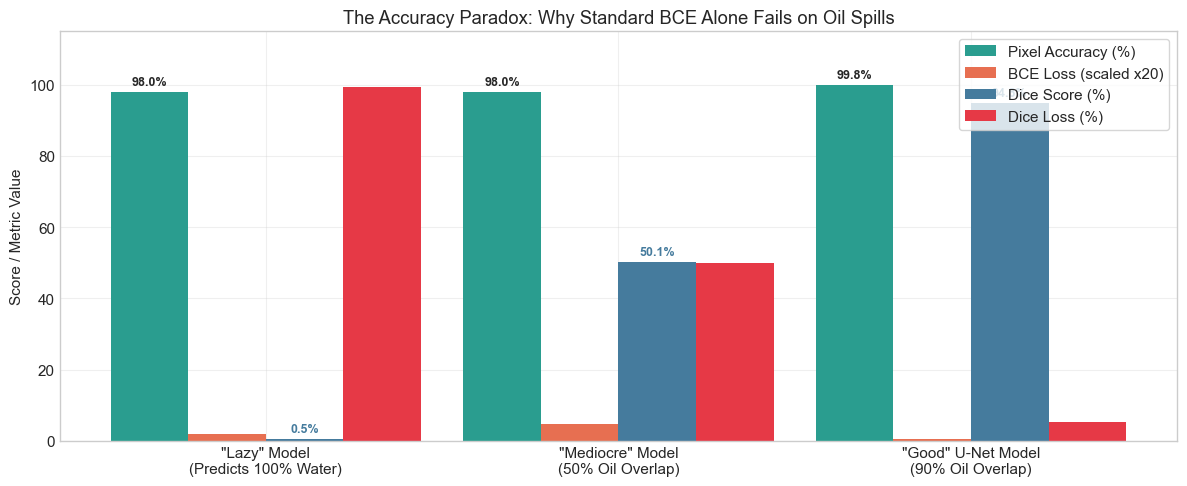

In [4]:
# Ground truth image: 10,000 pixels (200 oil spill pixels = 2%, 9800 sea pixels = 98%)
N = 10000
true_oil = 200
true_water = 9800
y_true = np.zeros(N)
y_true[:true_oil] = 1.0  # 2% oil

# Scenario 1: A "Lazy" Dummy Model that always predicts 0.01 (clean water everywhere)
pred_lazy = np.full(N, 0.01)

# Scenario 2: A Mediocre Model that gets 50% overlap on oil with some false positives
pred_mediocre = np.zeros(N)
pred_mediocre[:100] = 0.90       # 100 true positives
pred_mediocre[true_oil:true_oil+100] = 0.90 # 100 false positives
pred_mediocre[true_oil+100:] = 0.05

# Scenario 3: An Accurate Model that predicts 90% of oil correctly with high confidence
pred_good = np.zeros(N)
pred_good[:180] = 0.95           # 180 true positives
pred_good[180:true_oil] = 0.10   # 20 false negatives
pred_good[true_oil:] = 0.02      # clean water

def compute_metrics(y_t, y_p):
    eps = 1e-7
    y_p_clip = np.clip(y_p, eps, 1 - eps)
    bce = -np.mean(y_t * np.log(y_p_clip) + (1 - y_t) * np.log(1 - y_p_clip))
    bin_p = (y_p > 0.5).astype(int)
    acc = np.mean(bin_p == y_t) * 100.0
    intersection = np.sum(y_t * (y_p > 0.5))
    dice = (2.0 * intersection + 1.0) / (np.sum(y_t) + np.sum(y_p > 0.5) + 1.0)
    dice_loss = 1.0 - dice
    return acc, bce, dice, dice_loss

scenarios = ['"Lazy" Model\n(Predicts 100% Water)', '"Mediocre" Model\n(50% Oil Overlap)', '"Good" U-Net Model\n(90% Oil Overlap)']
preds = [pred_lazy, pred_mediocre, pred_good]

accs, bces, dices, dice_losses = zip(*[compute_metrics(y_true, p) for p in preds])

x = np.arange(len(scenarios))
width = 0.22

fig, ax1 = plt.subplots(figsize=(12, 5))

rects1 = ax1.bar(x - 1.5*width, accs, width, label='Pixel Accuracy (%)', color='#2a9d8f')
rects2 = ax1.bar(x - 0.5*width, [b*20 for b in bces], width, label='BCE Loss (scaled x20)', color='#e76f51')
rects3 = ax1.bar(x + 0.5*width, [d*100 for d in dices], width, label='Dice Score (%)', color='#457b9d')
rects4 = ax1.bar(x + 1.5*width, [dl*100 for dl in dice_losses], width, label='Dice Loss (%)', color='#e63946')

ax1.set_title('The Accuracy Paradox: Why Standard BCE Alone Fails on Oil Spills')
ax1.set_xticks(x)
ax1.set_xticklabels(scenarios)
ax1.set_ylabel('Score / Metric Value')
ax1.set_ylim(0, 115)
ax1.legend(loc='upper right', frameon=True)
ax1.grid(True, alpha=0.3)

for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for rect in rects3:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#457b9d')

plt.tight_layout()
plt.show()


---
## 3. Optimizers: Why Adam? (Momentum + RMSProp)

### ❓ The Viva Questions:
* **Q1:** *Why didn't you use standard Stochastic Gradient Descent (SGD)?*
* **Q2:** *How does Momentum prevent zig-zag oscillations across steep canyons?*
* **Q3:** *What does RMSProp add that makes Adam so powerful?*

Let us plot the optimization trajectories on a simulated **elongated ravine loss surface** ($f(w_1, w_2) = 0.08w_1^2 + 1.8w_2^2$):


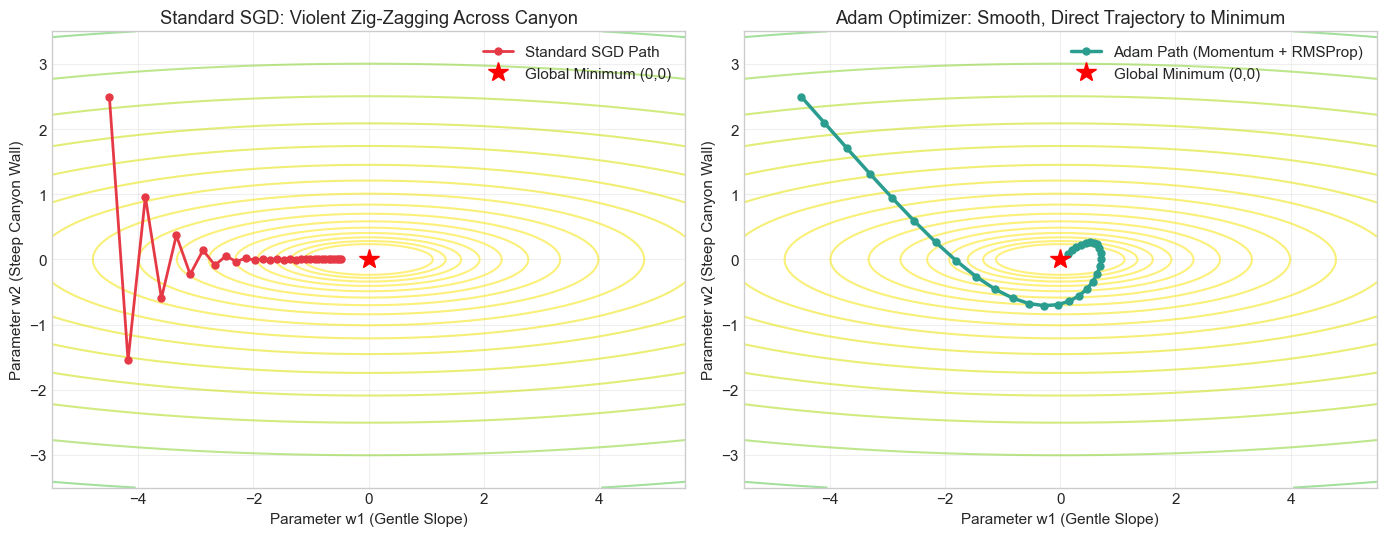

In [5]:
def loss_func(w1, w2):
    return 0.08 * (w1 ** 2) + 1.8 * (w2 ** 2)

def grad_func(w1, w2):
    return np.array([0.16 * w1, 3.6 * w2])

# Standard SGD (oscillates across the steep w2 walls)
def run_sgd(lr=0.45, steps=30):
    w = np.array([-4.5, 2.5])
    path = [w.copy()]
    for _ in range(steps):
        g = grad_func(w[0], w[1])
        w -= lr * g
        path.append(w.copy())
    return np.array(path)

# Adam Optimizer (Momentum + Adaptive RMSProp)
def run_adam(lr=0.4, beta1=0.85, beta2=0.999, steps=30):
    w = np.array([-4.5, 2.5])
    m = np.zeros(2)
    v = np.zeros(2)
    path = [w.copy()]
    for t in range(1, steps + 1):
        g = grad_func(w[0], w[1])
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * (g ** 2)
        m_hat = m / (1 - beta1 ** t)
        v_hat = v / (1 - beta2 ** t)
        w -= lr * m_hat / (np.sqrt(v_hat) + 1e-8)
        path.append(w.copy())
    return np.array(path)

path_sgd = run_sgd()
path_adam = run_adam()

w1_grid = np.linspace(-5.5, 5.5, 300)
w2_grid = np.linspace(-3.5, 3.5, 300)
W1, W2 = np.meshgrid(w1_grid, w2_grid)
Z = loss_func(W1, W2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].contour(W1, W2, Z, levels=np.logspace(-1, 2, 20), cmap='viridis_r', alpha=0.6)
axes[0].plot(path_sgd[:, 0], path_sgd[:, 1], 'o-', color='#e63946', linewidth=2, markersize=5, label='Standard SGD Path')
axes[0].plot(0, 0, 'r*', markersize=15, label='Global Minimum (0,0)')
axes[0].set_title('Standard SGD: Violent Zig-Zagging Across Canyon')
axes[0].set_xlabel('Parameter w1 (Gentle Slope)')
axes[0].set_ylabel('Parameter w2 (Steep Canyon Wall)')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

axes[1].contour(W1, W2, Z, levels=np.logspace(-1, 2, 20), cmap='viridis_r', alpha=0.6)
axes[1].plot(path_adam[:, 0], path_adam[:, 1], 'o-', color='#2a9d8f', linewidth=2.5, markersize=5, label='Adam Path (Momentum + RMSProp)')
axes[1].plot(0, 0, 'r*', markersize=15, label='Global Minimum (0,0)')
axes[1].set_title('Adam Optimizer: Smooth, Direct Trajectory to Minimum')
axes[1].set_xlabel('Parameter w1 (Gentle Slope)')
axes[1].set_ylabel('Parameter w2 (Steep Canyon Wall)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---
## 4. Data Normalization: Why Divide by 255.0?

### ❓ The Viva Question:
* **Sir:** *Why did you write `image / 255.0`? What happens if you remove that line?*

If you feed unscaled integers $[0, 255]$ into a neural network:
1. **Unbalanced Loss Surface:** The loss surface becomes an extremely stretched ellipse.
2. **Normalized Data $[0.0, 1.0]$:** The loss surface becomes a **symmetric spherical bowl**, allowing equal gradient descent steps in all directions.


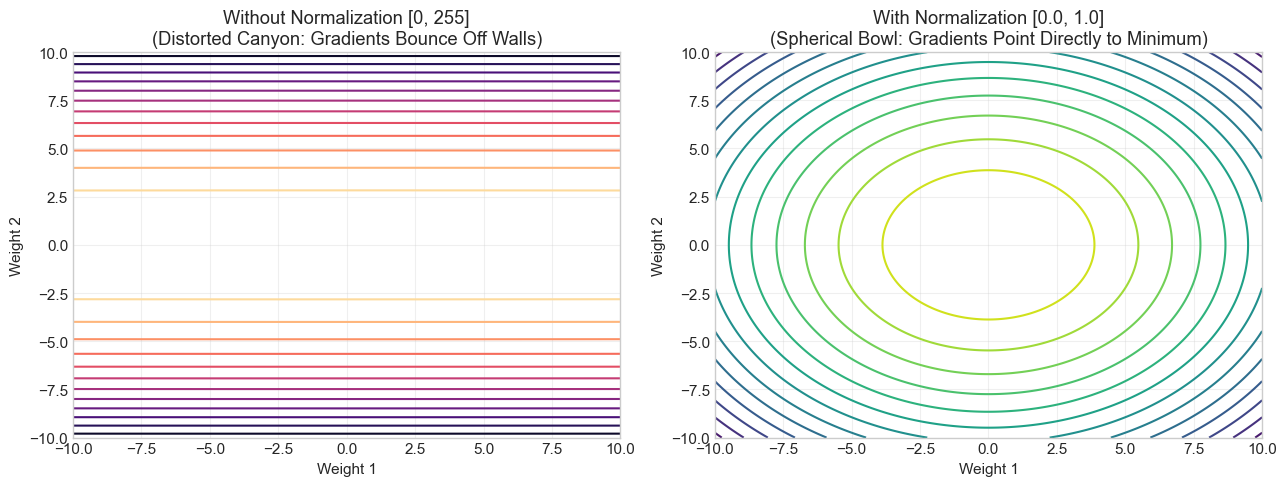

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

u_x = np.linspace(-10, 10, 200)
u_y = np.linspace(-10, 10, 200)
UX, UY = np.meshgrid(u_x, u_y)
Loss_unnorm = 0.001 * (UX ** 2) + 2.5 * (UY ** 2)

axes[0].contour(UX, UY, Loss_unnorm, levels=15, cmap='magma_r')
axes[0].set_title('Without Normalization [0, 255]\n(Distorted Canyon: Gradients Bounce Off Walls)')
axes[0].set_xlabel('Weight 1')
axes[0].set_ylabel('Weight 2')
axes[0].grid(True, alpha=0.3)

Loss_norm = 1.0 * (UX ** 2) + 1.0 * (UY ** 2)
axes[1].contour(UX, UY, Loss_norm, levels=15, cmap='viridis_r')
axes[1].set_title('With Normalization [0.0, 1.0]\n(Spherical Bowl: Gradients Point Directly to Minimum)')
axes[1].set_xlabel('Weight 1')
axes[1].set_ylabel('Weight 2')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---
## 5. Live Architecture Verification

Let us build our U-Net model and inspect the exact parameter count.


In [7]:
from backend.utils import build_unet, preprocess_image, postprocess_mask, compute_coverage, is_spill_detected, bce_dice_loss, dice_coefficient, iou_score

print("Building U-Net model with base_filters=16...")
mini_model = build_unet(input_shape=(256, 256, 3), base_filters=16)

trainable_count = sum([p.numpy().size for p in mini_model.trainable_weights])
non_trainable_count = sum([p.numpy().size for p in mini_model.non_trainable_weights])

print(f"Total Parameters:         {mini_model.count_params():,}")
print(f"Trainable Parameters:     {trainable_count:,}")
print(f"Non-Trainable Parameters: {non_trainable_count:,}")


Building U-Net model with base_filters=16...
Total Parameters:         1,945,521
Trainable Parameters:     1,942,577
Non-Trainable Parameters: 2,944


---
## 6. Real Satellite Scene Inference & Visual Overlay

Let us load a real SAR satellite test image from `sample_data/images`, run it through our trained model weights (`models/oil_spill_unet.keras`), and display:
1. **Raw Satellite SAR Image**
2. **Ground Truth Mask**
3. **Model Predicted Spill Mask + Red Highlight Overlay**


Loaded trained weights from: models\oil_spill_unet.keras


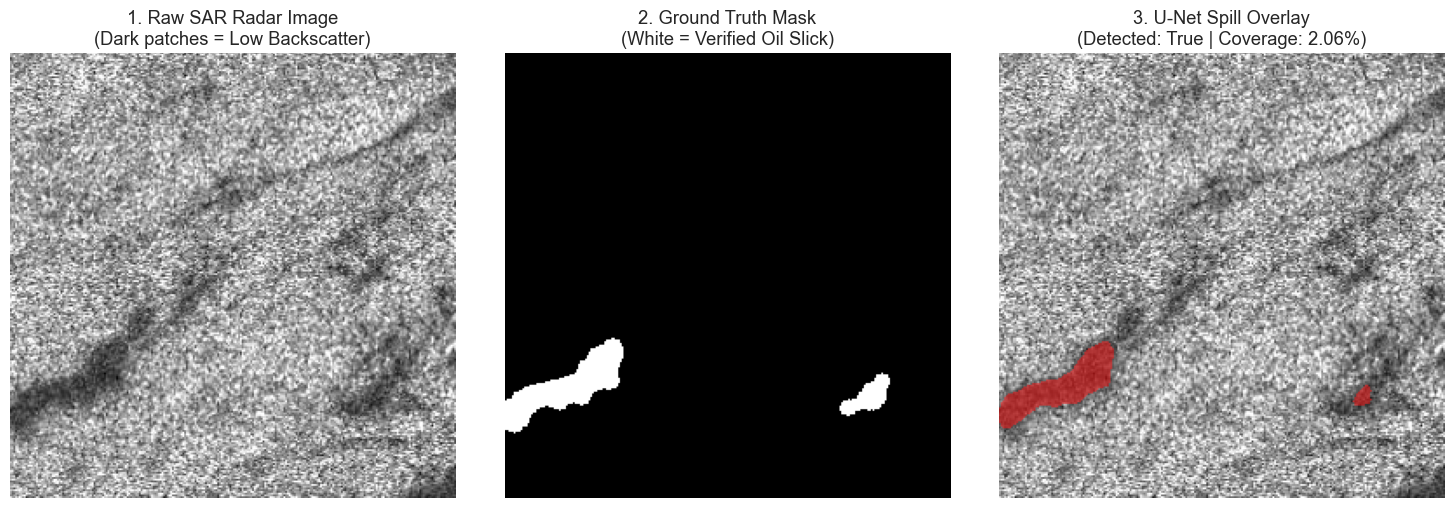

Detection Verdict: 🚨 OIL SPILL DETECTED!
Estimated Spill Coverage: 2.06%


In [8]:
from backend.utils import load_saved_model

# Load best saved weights
model_path = os.path.join("models", "oil_spill_unet.keras")
if not os.path.exists(model_path):
    model_path = os.path.join("..", "models", "oil_spill_unet.keras")

trained_model = load_saved_model(model_path)
print("Loaded trained weights from:", model_path)

# Pick benchmark test image (palsar_100.png has a prominent oil slick)
test_img_path = os.path.join("sample_data", "images", "palsar_100.png")
test_mask_path = os.path.join("sample_data", "masks", "palsar_100.png")

raw_img = Image.open(test_img_path)
true_mask = Image.open(test_mask_path) if os.path.exists(test_mask_path) else None

# Preprocess & Predict
inp = preprocess_image(raw_img)
raw_pred = trained_model.predict(inp, verbose=0)
binary_mask = postprocess_mask(raw_pred, threshold=0.5, original_size=raw_img.size)
coverage = compute_coverage(binary_mask)
detected = is_spill_detected(coverage, min_pct=0.5)

# Create Red Overlay
rgb_base = raw_img.convert("RGB")
overlay_np = np.array(rgb_base)
spill_pixels = binary_mask > 127
overlay_np[spill_pixels] = (255, 30, 30) # Bright red highlight
blended_img = Image.blend(rgb_base, Image.fromarray(overlay_np), alpha=0.55)

# Plot 3-Panel Inspection
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(raw_img, cmap='gray')
axes[0].set_title('1. Raw SAR Radar Image\n(Dark patches = Low Backscatter)')
axes[0].axis('off')

if true_mask is not None:
    axes[1].imshow(true_mask, cmap='gray')
    axes[1].set_title('2. Ground Truth Mask\n(White = Verified Oil Slick)')
else:
    axes[1].imshow(binary_mask, cmap='gray')
    axes[1].set_title('2. Predicted Binary Mask')
axes[1].axis('off')

axes[2].imshow(blended_img)
axes[2].set_title(f'3. U-Net Spill Overlay\n(Detected: {detected} | Coverage: {coverage:.2f}%)')
axes[2].axis('off')

plt.tight_layout()
plt.show()
print(f"Detection Verdict: {'🚨 OIL SPILL DETECTED!' if detected else 'CLEAN WATER / NO SPILL'}")
print(f"Estimated Spill Coverage: {coverage:.2f}%")
